In [ ]:
# Install dependencies (run once)
%pip install tabpfn shap missforest openpyxl joblib --quiet

Note: you may need to restart the kernel to use updated packages.


In [25]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder,PowerTransformer,QuantileTransformer,MinMaxScaler
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import r2_score, mean_squared_error
from missforest import MissForest
from lightgbm import LGBMRegressor
import shap as s
from sklearn.inspection import PartialDependenceDisplay
from sklearn.model_selection import cross_val_predict
from scipy.optimize import differential_evolution
from scipy.spatial.distance import cdist
from itertools import combinations
import random
from joblib import Parallel, delayed
import multiprocessing
import optuna as op
# Reproducibility
RANDOM_STATE = 62

# Column config — centralised so changes propagate everywhere
TARGET_COL   = 'f_SAR_W_g'
CAT_COLS      = ['c_shape_type', 'c_magnetic_phase', 'c_coating']
DROP_COLS     = ['-', 'DOI', 'c_core_composition', 'c_dopant_element', 'f_dopant_ratio']
FEATURE_NAMES = [
    'f_avg_core_width_nm', 'f_Ms_emu_g_MNP', 'f_Hc_Oe', 'is_doped',
    'c_coating', 'f_H_Oe', 'f_FCY_kHz', 'f_conc_MNP_mg_mL',
    'c_shape_type', 'c_magnetic_phase', 'f_avg_core_sd_nm _BOTH',
    'Ca_comp', 'Co_comp', 'Cu_comp', 'Fe_comp', 'Ga_comp', 'Gd_comp',
    'Mg_comp', 'Mn_comp', 'Nd_comp', 'Ni_comp', 'Sn_comp', 'Tb_comp',
    'Zn_comp', 'f_magnetic_anisotropy', 'f_magnetic_dipole_moment',
]

In [12]:
def clean_column_names(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [
        c.replace('\ufeff', '').replace('\u200b', '').strip()
        for c in df.columns
    ]
    return df


df_raw = pd.read_excel("/kaggle/input/datasets/magneticmaterials/hyperthermia/Final.xlsx")
df_raw = clean_column_names(df_raw)

# Drop identifier/non-feature columns that exist in this dataset
cols_to_drop = [c for c in DROP_COLS if c in df_raw.columns]
df = df_raw.drop(columns=cols_to_drop)

print(f"Loaded {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Loaded 1548 rows × 33 columns


,S. No.,f_avg_core_width_nm,f_Ms_emu_g_MNP,f_Hc_Oe,is_doped,f_is_coated,f_is_organic,f_is_inorganic,f_is_composite_coating,c_coating,...,Fe_comp,Ga_comp,Gd_comp,Mg_comp,Mn_comp,Nd_comp,Ni_comp,Sn_comp,Tb_comp,Zn_comp
0,1,15.0,60.00,0.0,0,0,0,0,0,NaN,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
1,2,17.0,36.78,6.0,1,1,1,0,0,Chitosan,...,2.93,0.0,0.07,0.0,0.0,0.0,0.0,0,0.0,0.0
2,3,75.0,60.00,100.0,0,0,0,0,0,NaN,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
3,4,19.9,53.10,4.0,0,1,1,0,0,TREG-coated,...,2.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0
4,5,14.6,54.40,3.0,0,0,0,0,0,NaN,...,3.00,0.0,0.00,0.0,0.0,0.0,0.0,0,0.0,0.0


In [13]:
target_col = TARGET_COL.replace('\ufeff', '').replace('\u200b', '').strip()
X = df.drop(columns=[target_col])
y = df[target_col]

# 80 / 10 / 10 split
x_train, x_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

print(f"Train : {x_train.shape[0]} rows")
print(f"Val   : {x_val.shape[0]} rows")
print(f"Test  : {x_test.shape[0]} rows  ← locked until final evaluation")

Train : 1238 rows
Val   : 155 rows
Test  : 155 rows  ← locked until final evaluation


In [14]:
# --- 5a. Binary presence indicators (fit-free, safe to apply before split logic) ---
def add_presence_flags(df_in: pd.DataFrame) -> pd.DataFrame:
    df_out = df_in.copy()
    df_out['f_is_coated']  = df_out['c_coating'].notna().astype(int)
    df_out['f_is_shaped']  = df_out['c_shape_type'].notna().astype(int)
    df_out['f_is_phased']  = df_out['c_magnetic_phase'].notna().astype(int)
    return df_out

x_train = add_presence_flags(x_train)
x_val   = add_presence_flags(x_val)
x_test  = add_presence_flags(x_test)

In [15]:
# --- 5b. Categorical encoding ---
# Fill NaN → 'Unknown' for unseen categories, then ordinal-encode.
# Where the presence flag == 0 (field was missing), force the encoded value to -1.
# Encoders are fit on train only.

def encode_categorical(train_df, val_df, test_df, cat_col, flag_col):
    for df_part in [train_df, val_df, test_df]:
        df_part[cat_col] = df_part[cat_col].fillna('Unknown').astype(str)

    enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    train_df[cat_col] = enc.fit_transform(train_df[[cat_col]])
    val_df[cat_col]   = enc.transform(val_df[[cat_col]])
    test_df[cat_col]  = enc.transform(test_df[[cat_col]])

    for df_part in [train_df, val_df, test_df]:
        df_part.loc[df_part[flag_col] == 0, cat_col] = -1
        df_part.drop(columns=[flag_col], inplace=True)

    return train_df, val_df, test_df

x_train, x_val, x_test = encode_categorical(x_train, x_val, x_test, 'c_coating',       'f_is_coated')
x_train, x_val, x_test = encode_categorical(x_train, x_val, x_test, 'c_shape_type',    'f_is_shaped')
x_train, x_val, x_test = encode_categorical(x_train, x_val, x_test, 'c_magnetic_phase', 'f_is_phased')

print("Encoding done. x_train shape:", x_train.shape)

Encoding done. x_train shape: (1238, 31)


In [16]:
# --- 5c. Numeric imputation (fit on train only) ---
numeric_cols = x_train.select_dtypes(include=np.number).columns.tolist()

imputer = MissForest(rgr=RandomForestRegressor(n_estimators=100,random_state=62),max_iter=10)

if x_train[numeric_cols].isnull().any().any():
    x_train[numeric_cols] = imputer.fit_transform(x_train[numeric_cols])
    x_val[numeric_cols]   = imputer.transform(x_val[numeric_cols])
    x_test[numeric_cols]  = imputer.transform(x_test[numeric_cols])
    print("Imputation applied.")
else:
    print("No missing values in numeric columns — skipping imputation.")

/usr/local/lib/python3.13/dist-packages/missforest/missforest.py:333: UserWarning: Label encoding is no longer performed by default. Users will have to perform categorical features encoding by themselves.
  warnings.warn("Label encoding is no longer performed by default. "
 30%|███       | 3/10 [01:08<02:41, 23.12s/it]/usr/local/lib/python3.13/dist-packages/missforest/missforest.py:303: UserWarning: NRMSE increased.
  warnings.warn("NRMSE increased.")
/usr/local/lib/python3.13/dist-packages/missforest/missforest.py:453: UserWarning: Stopping criterion triggered during fitting. Before last imputation matrix will be returned.
  warnings.warn(
 30%|███       | 3/10 [01:31<03:32, 30.42s/it]
/usr/local/lib/python3.13/dist-packages/missforest/missforest.py:490: UserWarning: Label encoding is no longer performed by default. Users will have to perform categorical features encoding by themselves.
  warnings.warn("Label encoding is no longer performed by default. "
/usr/local/lib/python3.13/dist

Imputation applied.


In [17]:
# --- 6a. Feature scaling (QuantileTransformer, fit on train only) ---
transf = QuantileTransformer(random_state=RANDOM_STATE)

x_train_scaled = transf.fit_transform(x_train)
x_val_scaled   = transf.transform(x_val)
x_test_scaled  = transf.transform(x_test)

print("Scaling done. Train shape:", x_train_scaled.shape)

Scaling done. Train shape: (1238, 31)


In [22]:
# --- 6b. Log transformation ---
y_train_log = np.log1p(y_train.values.astype(float))   # log1p on raw SAR
y_val_log   = np.log1p(y_val.values.astype(float))
y_test_log  = np.log1p(y_test.values.astype(float))

scaler = MinMaxScaler()
y_train_scaled = scaler.fit_transform(y_train_log.reshape(-1, 1)).flatten()
y_val_scaled   = scaler.transform(y_val_log.reshape(-1, 1)).flatten()
y_test_scaled  = scaler.transform(y_test_log.reshape(-1, 1)).flatten()

print("=== Scaler sanity check ===")
print(f"  data_min_ : {scaler.data_min_[0]:.4f}  "
      f"(= log1p({np.expm1(scaler.data_min_[0]):.2f} W/g)")
print(f"  data_max_ : {scaler.data_max_[0]:.4f}  "
      f"(= log1p({np.expm1(scaler.data_max_[0]):.2f} W/g)")
assert scaler.data_max_[0] > 1.0, \
    "Scaler data_max_ is still wrong — y_train may still be pre-transformed. Restart kernel and rerun top-to-bottom."

# Use these as your targets for model training (rename to match rest of notebook)
y_train = y_train_scaled
y_val   = y_val_scaled
y_test  = y_test_scaled


=== Scaler sanity check ===
  data_min_ : 0.1570  (= log1p(0.17 W/g)
  data_max_ : 8.6145  (= log1p(5510.00 W/g)


In [23]:
def inverse_sar(y_scaled: np.ndarray, fitted_scaler: MinMaxScaler) -> np.ndarray:
  y_scaled_clipped = np.clip(y_scaled, 0.0, 1.0)
  pred_log_units      = fitted_scaler.inverse_transform(y_scaled_clipped.reshape(-1, 1)).flatten()
  true_predicted_sar  = np.expm1(pred_log_units)
  return true_predicted_sar

In [28]:
def objective(trial):
    params = dict(
        n_estimators      = trial.suggest_int('n_estimators', 50, 1000),
        learning_rate     = trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        num_leaves        = trial.suggest_int('num_leaves', 20, 150),
        max_depth         = trial.suggest_int('max_depth', 3, 15),
        min_child_samples = trial.suggest_int('min_child_samples', 5, 50),
        subsample         = trial.suggest_float('subsample', 0.5, 1.0),
        colsample_bytree  = trial.suggest_float('colsample_bytree', 0.5, 1.0)
    )
    
    lgb = LGBMRegressor(**params, random_state=RANDOM_STATE, verbose=-1)
    
    lgb.fit(x_train_scaled, y_train)
    
    preds = lgb.predict(x_val_scaled)
    
    rmse = np.sqrt(mean_squared_error(y_val, inverse_sar(preds, scaler)))
    
    return rmse

study = op.create_study(
    direction='minimize',
    sampler=op.samplers.TPESampler(seed=RANDOM_STATE),
    storage='sqlite:///lgb_regression_optuna.db',
    load_if_exists=True,
)

study.optimize(objective, n_trials=150) 

print("Best params :", study.best_params)
print("Best val RMSE:", round(study.best_value, 4))

[I 2026-10-12 07:52:14,067] A new study created in RDB with name: no-name-76aa7f5e-5a3a-47f7-ab1f-a053e86dade5
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
[I 2026-10-12 07:52:14,251] Trial 0 finished with value: 75.57179458840801 and parameters: {'n_estimators': 82, 'learning_rate': 0.009510755474627637, 'num_leaves': 130, 'max_depth': 8, 'min_child_samples': 34, 'subsample': 0.645471618633067, 'colsample_bytree': 0.7714001444651046}. Best is trial 0 with value: 75.57179458840801.
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
[I 2026-10-12 07:52:15,283] Trial 1 finished with value: 85.7210451977256 and parameters: {'n_estimators': 267, 'learning_rate': 0.003023797188113821, 'num_leaves': 144, 'max_depth

Best params : {'n_estimators': 52, 'learning_rate': 0.0011630855268806182, 'num_leaves': 145, 'max_depth': 6, 'min_child_samples': 16, 'subsample': 0.9738725322244136, 'colsample_bytree': 0.7276144456160865}
Best val RMSE: 59.1492


In [29]:
lgb = LGBMRegressor(**study.best_params, random_state=RANDOM_STATE, verbose=-1)
lgb.fit(x_train_scaled, y_train)

LGBMRegressor(colsample_bytree=0.7276144456160865,
              learning_rate=0.0011630855268806182, max_depth=6,
              min_child_samples=16, n_estimators=52, num_leaves=145,
              random_state=62, subsample=0.9738725322244136, verbose=-1)

In [31]:
y_val_pred  = lgb.predict(x_val_scaled)
y_test_pred = lgb.predict(x_test_scaled)

val_r2    = r2_score(y_val,  y_val_pred)
test_r2   = r2_score(y_test, y_test_pred)
val_rmse  = np.sqrt(mean_squared_error(y_val, y_val_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

y_test_inv      = inverse_sar(y_test, scaler)
y_test_pred_inv = inverse_sar(y_test_pred, scaler)
err_90          = np.quantile(np.abs(y_test_inv - y_test_pred_inv), 0.90)

print(f"Validation  — R²: {val_r2:.4f}   RMSE: {val_rmse:.4f}")
print(f"Test        — R²: {test_r2:.4f}   RMSE: {test_rmse:.4f}")
print(f"90th-pct prediction error (test): ±{err_90:.4f}")

Validation  — R²: 0.0399   RMSE: 0.1641
Test        — R²: 0.0564   RMSE: 0.1550
90th-pct prediction error (test): ±244.1769


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


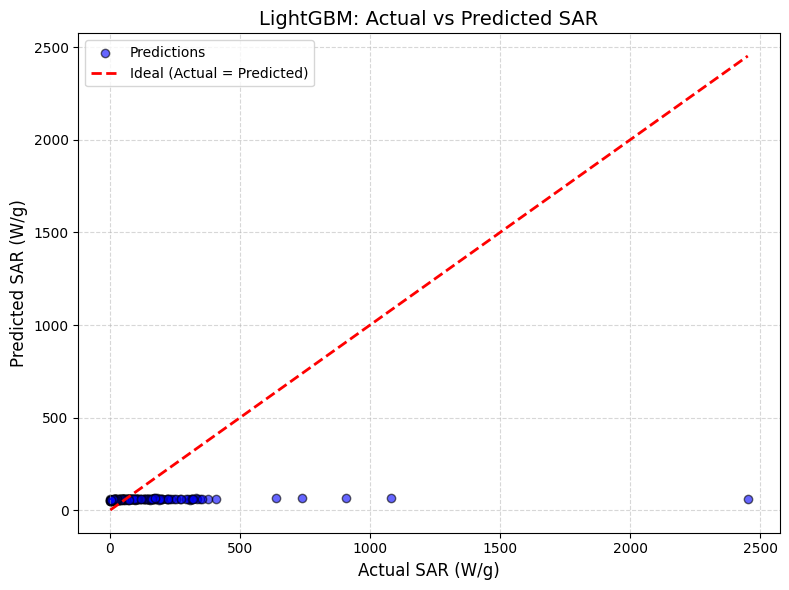

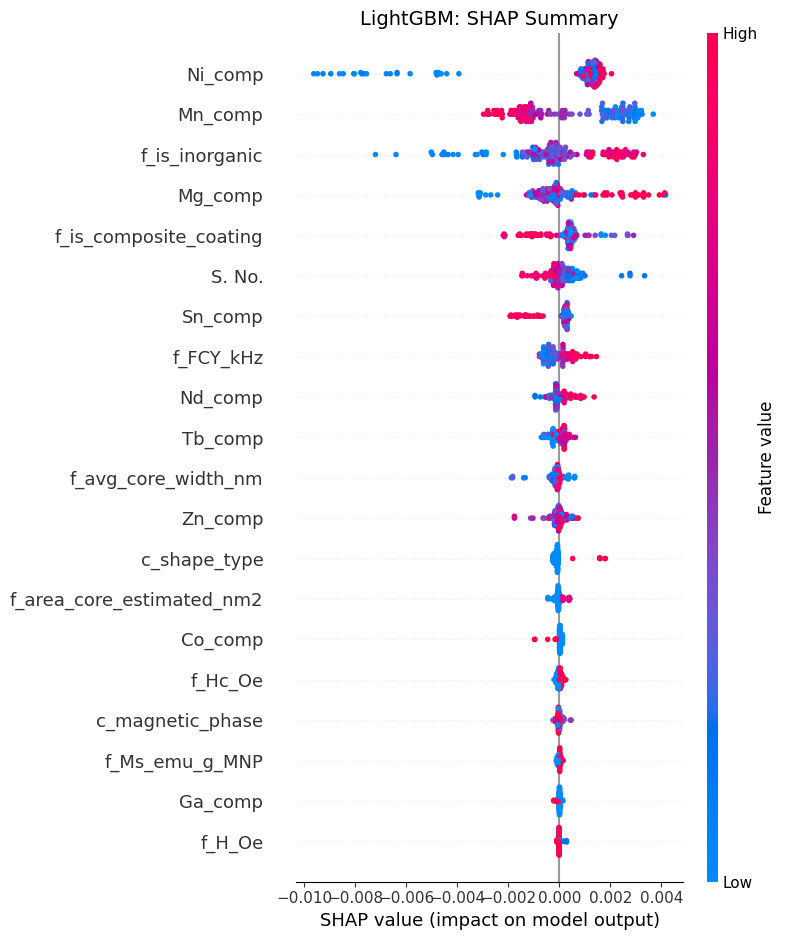

In [33]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_inv, y_test_pred_inv, alpha=0.6, color='blue', edgecolor='k', label='Predictions')
min_val = min(np.min(y_test_inv), np.min(y_test_pred_inv))
max_val = max(np.max(y_test_inv), np.max(y_test_pred_inv))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal (Actual = Predicted)')
plt.title('LightGBM: Actual vs Predicted SAR', fontsize=14)
plt.xlabel('Actual SAR (W/g)', fontsize=12)
plt.ylabel('Predicted SAR (W/g)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('lgb_actual_vs_predicted.png', dpi=600, bbox_inches='tight')
plt.show()
plt.close()

explainer = s.TreeExplainer(lgb)
shap_values = explainer.shap_values(x_test_scaled)
plt.figure(figsize=(10, 8))
s.summary_plot(shap_values, x_test_scaled, feature_names=x_test.columns, show=False)
plt.title('LightGBM: SHAP Summary', fontsize=14)
plt.tight_layout()
plt.savefig('lgb_shap_summary.png', dpi=600, bbox_inches='tight')
plt.show()
plt.close()